<a href="https://colab.research.google.com/github/punesamor-ui/ML_PROJECTSS_COMPILATION/blob/main/Decision_Tree_Classification_and_Regression_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Activity: Decision Tree — Classification and Regression
**Platform:** Google Colab  |  **Language:** Python  |  **Algorithm:** Decision Tree  
**Instruction:** Run all baseline cells before modifying the exercise cells at the end. The notebook uses generated datasets and needs no external files.

Decision trees classify samples by making feature-based splits and predict numerical values using the average target value in each terminal node. Your task is to use the visualizations and metrics to explain how tuning tree complexity affects model behavior.

## I. Activity Objectives
1. Differentiate Decision Tree classification and regression.
2. Interpret tree diagrams, decision boundaries, feature importance, confusion matrices, and regression predictions.
3. Investigate `max_depth`, `min_samples_leaf`, and dataset noise.
4. Analyze underfitting, overfitting, and generalization using **both training and held-out test metrics**.
5. Report evidence-based conclusions from experiments.

## II. Baseline Experiments (Diagrams 1–9)
Run each cell without changing the baseline parameters. Later, complete all five challenges in **IV. Student Exercises and Wrap-up**. Keep the baseline outputs for comparison.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error)

RANDOM_STATE = 42
BASELINE_NOISE = 0.22
BASELINE_DEPTH = 3
BASELINE_LEAF = 1
BASELINE_REG_DEPTH = 4
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False})
print('Ready. All datasets in this notebook are synthetic and reproducible.')

In [ ]:
def classification_data(noise=BASELINE_NOISE):
    X, y = make_moons(n_samples=450, noise=noise, random_state=RANDOM_STATE)
    return train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

def classification_model(X_train, y_train, depth=BASELINE_DEPTH, leaf=BASELINE_LEAF):
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                  criterion='gini', random_state=RANDOM_STATE).fit(X_train, y_train)

def classification_scores(model, X_train, X_test, y_train, y_test):
    return {'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
            'test_accuracy': accuracy_score(y_test, model.predict(X_test)),
            'nodes': model.tree_.node_count,
            'leaves': model.get_n_leaves()}

def draw_boundary(model, X, y, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(6, 4))
    x0, x1 = X[:, 0], X[:, 1]
    xx, yy = np.meshgrid(np.linspace(x0.min()-.5, x0.max()+.5, 230),
                         np.linspace(x1.min()-.5, x1.max()+.5, 230))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.23, cmap='coolwarm')
    ax.scatter(x0, x1, c=y, s=13, cmap='coolwarm', edgecolors='none', alpha=.75)
    ax.set(title=title, xlabel='Feature 1', ylabel='Feature 2')
    return ax

def regression_data():
    rng = np.random.default_rng(RANDOM_STATE)
    x = np.sort(6 * rng.random(220))
    y = np.sin(1.5*x) + .25*np.cos(3*x) + rng.normal(0, .23, size=x.shape)
    X = x.reshape(-1, 1)
    return train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)

def regression_model(X_train, y_train, depth=BASELINE_REG_DEPTH):
    return DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_train, y_train)

def regression_rmse(model, X, y):
    return np.sqrt(mean_squared_error(y, model.predict(X)))

def draw_regression_curve(model, X_train, y_train, X_test, y_test, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(7, 4))
    xx = np.linspace(0, 6, 600).reshape(-1, 1)
    ax.scatter(X_train[:,0], y_train, s=17, alpha=.53, label='Training samples')
    ax.scatter(X_test[:,0], y_test, s=18, alpha=.64, label='Test samples', marker='x')
    ax.plot(xx[:,0], model.predict(xx), color='black', linewidth=2, label='Tree prediction')
    ax.set(title=title, xlabel='Input feature', ylabel='Target')
    ax.legend(fontsize=8)
    return ax

X_train, X_test, y_train, y_test = classification_data()
classifier = classification_model(X_train, y_train)
Xr_train, Xr_test, yr_train, yr_test = regression_data()
regressor = regression_model(Xr_train, yr_train)
print('Classification split:', len(X_train), 'training /', len(X_test), 'test samples')
print('Regression split:', len(Xr_train), 'training /', len(Xr_test), 'test samples')

### Diagram 1 — Classification Dataset
Synthetic interleaving-moons data. Notice that the two classes overlap, so some errors are expected.

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='coolwarm', s=22, alpha=.75)
ax.set(title=f'Diagram 1 — Training Data (noise={BASELINE_NOISE})', xlabel='Feature 1', ylabel='Feature 2')
plt.show()

### Diagram 2 — Classification Tree Structure
Each split uses a feature threshold. A terminal node (leaf) outputs a class. Tree structures can become too large to display fully; `plot_tree` is limited to its first three levels for readability.

In [ ]:
fig, ax = plt.subplots(figsize=(13.5, 5.5))
plot_tree(classifier, max_depth=3, filled=True, rounded=True, fontsize=8,
          feature_names=['Feature 1','Feature 2'], class_names=['Class 0','Class 1'], ax=ax)
ax.set_title(f'Diagram 2 — Classification Tree (max_depth={BASELINE_DEPTH})')
plt.show()
print('Baseline classification:', classification_scores(classifier, X_train, X_test, y_train, y_test))

### Diagram 3 — Classification Decision Boundary
Decision trees produce axis-aligned, rectangular partition boundaries for these two numerical features.

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
draw_boundary(classifier, X_test, y_test, f'Diagram 3 — Test Set Boundary (depth={BASELINE_DEPTH})', ax=ax)
plt.show()

### Diagram 4 — Model Complexity: Train vs. Test Accuracy
Depth is varied while the **same data split** is held fixed. The highest training accuracy is not necessarily the highest test accuracy.

In [ ]:
depth_results=[]
for depth in range(1, 13):
    m=classification_model(X_train, y_train, depth=depth)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    depth_results.append({'max_depth': depth, **r})
depth_df=pd.DataFrame(depth_results)
display(depth_df[['max_depth','train_accuracy','test_accuracy','leaves']].round(3))
fig, ax=plt.subplots(figsize=(7,4.1))
ax.plot(depth_df.max_depth, depth_df.train_accuracy, 'o-', label='Training accuracy')
ax.plot(depth_df.max_depth, depth_df.test_accuracy, 's-', label='Test accuracy')
ax.set(title='Diagram 4 — Accuracy by Tree Depth', xlabel='max_depth', ylabel='Accuracy', ylim=(0,1.04))
ax.legend(); plt.show()

### Diagram 5 — Feature Importance
Importance describes the total weighted reduction in split criterion attributable to each feature; it does **not** prove causality.

In [ ]:
importance=pd.Series(classifier.feature_importances_, index=['Feature 1','Feature 2'])
fig, ax=plt.subplots(figsize=(5.7,3.8))
importance.plot(kind='bar', ax=ax)
ax.set(title='Diagram 5 — Feature Importances', ylabel='Importance', ylim=(0,1))
plt.xticks(rotation=0); plt.show()
print(importance.round(3).to_string())

### Diagram 6 — Classification Confusion Matrix
**Rows are true classes; columns are predicted classes.** For class 1 as the positive class, an off-diagonal top-right cell is a false positive; the bottom-left cell is a false negative.

In [ ]:
yp=classifier.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=['Class 0','Class 1'], cmap='Blues', values_format='d')
plt.title('Diagram 6 — Confusion Matrix (Baseline)'); plt.show()
print(classification_report(y_test, yp, zero_division=0))

### Diagram 7 — Regression Dataset
The regression target is a continuous value. The training samples include noise.

In [ ]:
fig, ax=plt.subplots(figsize=(7,4))
ax.scatter(Xr_train[:,0], yr_train, s=19, alpha=.75)
ax.set(title='Diagram 7 — Training Data for Regression', xlabel='Input feature', ylabel='Target')
plt.show()

### Diagram 8 — Regression Tree Structure
Regression leaves predict averages of the training targets within each terminal region.

In [ ]:
fig, ax=plt.subplots(figsize=(13.5,5))
plot_tree(regressor, max_depth=3, filled=True, rounded=True, fontsize=8, feature_names=['Input feature'], ax=ax)
ax.set_title(f'Diagram 8 — Regression Tree (max_depth={BASELINE_REG_DEPTH}; first 3 levels)')
plt.show()

### Diagram 9 — Regression Prediction Curve
A decision-tree regressor predicts a piecewise-constant (step-shaped) function. Evaluate prediction quality using **test RMSE**, not apparent smoothness.

In [ ]:
fig, ax=plt.subplots(figsize=(7,4.2))
draw_regression_curve(regressor, Xr_train, yr_train, Xr_test, yr_test,
                      f'Diagram 9 — Regression (depth={BASELINE_REG_DEPTH})', ax=ax)
plt.show()
print('Baseline train RMSE:', round(regression_rmse(regressor, Xr_train, yr_train),3))
print('Baseline test RMSE:', round(regression_rmse(regressor, Xr_test, yr_test),3))

## III. Student Exercises and Wrap-up
**Complete all five challenges.** In each exercise cell, change only the indicated value or list, rerun it, capture the resulting figure(s) and metrics, and write **3–5 sentences** explaining what you changed, what you observed, why the algorithm behaved that way, and what the experiment shows.

Before making changes, save the original baseline outputs. Do not claim that deeper trees or higher accuracy on the training set automatically mean better generalization.

```markdown
### ⚠️ IMPORTANT: Run Setup Cells First
Before executing the challenge cells below, make sure you have executed the cell under **II. Baseline Experiments** (specifically Cell `3a693cb3` which imports modules and defines helper functions like `classification_model`, `classification_data`, and `regression_model`). Otherwise, you will encounter `NameError` exceptions.
```

In [8]:
# === MANDATORY SETUP CELL ===
# This cell re-imports all necessary libraries, defines the data generators,
# and instantiates helper functions so that the challenges below will run.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error)

RANDOM_STATE = 42
BASELINE_NOISE = 0.22
BASELINE_DEPTH = 3
BASELINE_LEAF = 1
BASELINE_REG_DEPTH = 4
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False})

def classification_data(noise=BASELINE_NOISE):
    X, y = make_moons(n_samples=450, noise=noise, random_state=RANDOM_STATE)
    return train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

def classification_model(X_train, y_train, depth=BASELINE_DEPTH, leaf=BASELINE_LEAF):
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                  criterion='gini', random_state=RANDOM_STATE).fit(X_train, y_train)

def classification_scores(model, X_train, X_test, y_train, y_test):
    return {'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
            'test_accuracy': accuracy_score(y_test, model.predict(X_test)),
            'nodes': model.tree_.node_count,
            'leaves': model.get_n_leaves()}

def draw_boundary(model, X, y, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(6, 4))
    x0, x1 = X[:, 0], X[:, 1]
    xx, yy = np.meshgrid(np.linspace(x0.min()-.5, x0.max()+.5, 230),
                         np.linspace(x1.min()-.5, x1.max()+.5, 230))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.23, cmap='coolwarm')
    ax.scatter(x0, x1, c=y, s=13, cmap='coolwarm', edgecolors='none', alpha=.75)
    ax.set(title=title, xlabel='Feature 1', ylabel='Feature 2')
    return ax

def regression_data():
    rng = np.random.default_rng(RANDOM_STATE)
    x = np.sort(6 * rng.random(220))
    y = np.sin(1.5*x) + .25*np.cos(3*x) + rng.normal(0, .23, size=x.shape)
    X = x.reshape(-1, 1)
    return train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)

def regression_model(X_train, y_train, depth=BASELINE_REG_DEPTH):
    return DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_train, y_train)

def regression_rmse(model, X, y):
    return np.sqrt(mean_squared_error(y, model.predict(X)))

def draw_regression_curve(model, X_train, y_train, X_test, y_test, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(7, 4))
    xx = np.linspace(0, 6, 600).reshape(-1, 1)
    ax.scatter(X_train[:,0], y_train, s=17, alpha=.53, label='Training samples')
    ax.scatter(X_test[:,0], y_test, s=18, alpha=.64, label='Test samples', marker='x')
    ax.plot(xx[:,0], model.predict(xx), color='black', linewidth=2, label='Tree prediction')
    ax.set(title=title, xlabel='Input feature', ylabel='Target')
    ax.legend(fontsize=8)
    return ax

# Initialize default splits
X_train, X_test, y_train, y_test = classification_data()
Xr_train, Xr_test, yr_train, yr_test = regression_data()
print("Setup completed successfully. Ready to run Challenges!")

Setup completed successfully. Ready to run Challenges!


### Challenge 1 — Tree Depth and Structure (Diagrams 2–3)
**Required modification:** Replace the default `depths = [3]` with **`[1, 3, 8]`**. Compare tree diagrams, nodes, leaves, decision boundaries, and training/test accuracy. The diagram truncates the displayed tree at three levels; the depth-8 model itself is **not** truncated.

**Interpretation (3–5 sentences):** What changed about the partitions and model complexity? Which depth generalized best on the test data?

```markdown
### 🔍 HIGHLIGHT — CHALLENGE 1
* **Default Value:** `depths = [3]`
* **Modified Value:** `depths = [1, 3, 8]`
* **Focus:** Observe how tree structure complexity and decision boundaries evolve as maximum depth is increased.
```

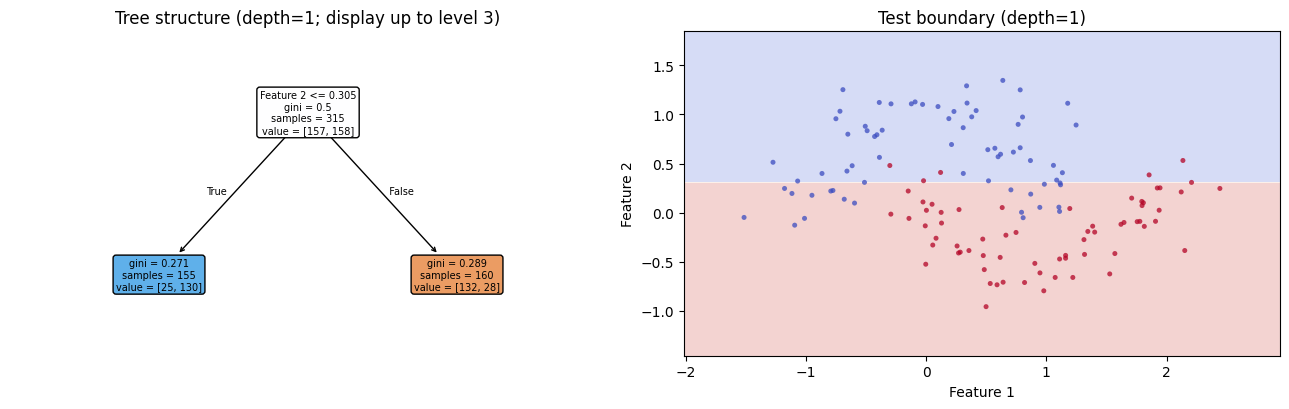

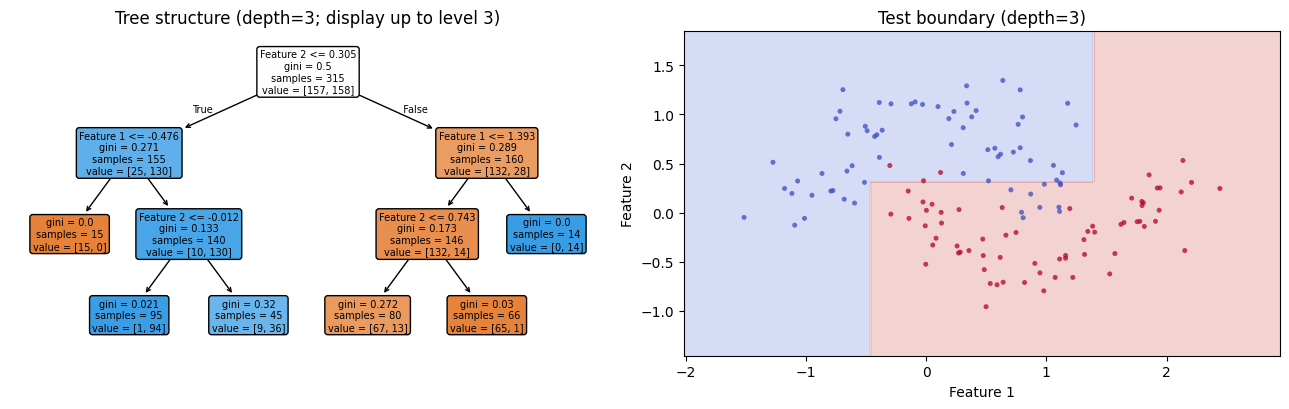

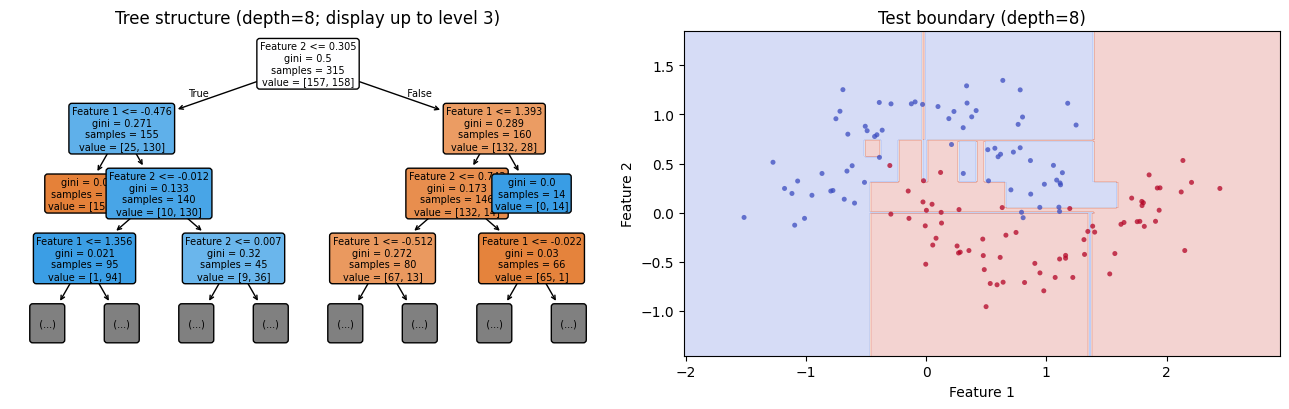

,depth,train_accuracy,test_accuracy,nodes,leaves
0,1,0.832,0.807,3,2
1,3,0.924,0.904,11,6
2,8,0.994,0.956,49,25


In [9]:
# CHALLENGE 1 — STUDENT MODIFICATION
# TODO: change [3] to [1, 3, 8]
depths = [1, 3, 8]
results=[]
for d in depths:
    m=classification_model(X_train, y_train, depth=d)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'depth':d, **r})
    fig, axes=plt.subplots(1,2,figsize=(13,4.2))
    plot_tree(m, max_depth=3, filled=True, rounded=True, fontsize=7,
              feature_names=['Feature 1','Feature 2'], ax=axes[0])
    axes[0].set_title(f'Tree structure (depth={d}; display up to level 3)')
    draw_boundary(m, X_test, y_test, f'Test boundary (depth={d})', axes[1])
    plt.tight_layout(); plt.show()
display(pd.DataFrame(results).round(3))

### Challenge 2 — Minimum Samples per Leaf (Diagram 3)
**Required modification:** Replace `leaf_values = [1]` with **`[1, 5, 15]`**. Keep `max_depth=8`, the split, and noise fixed. Compare decision boundaries, complexity, and training/test accuracy.

**Interpretation (3–5 sentences):** How does restricting leaf size change the fitted regions? Does reducing complexity improve test performance for these data?

```markdown
### 🔍 HIGHLIGHT — CHALLENGE
* **Default Value:** `leaf_values = [1]`
* **Modified Value:** `leaf_values = [1, 5, 15]`
* **Focus:** Observe the smoothing effect on the decision boundary as you require more samples per leaf node.
```

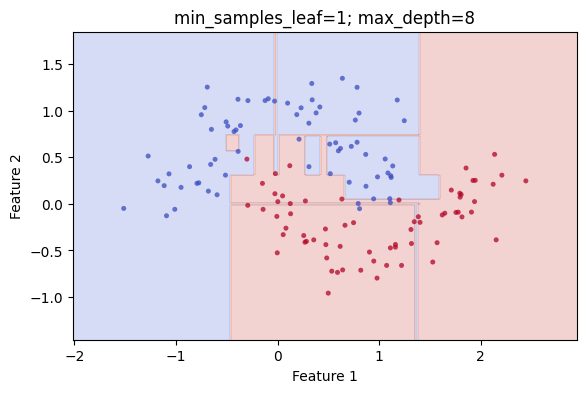

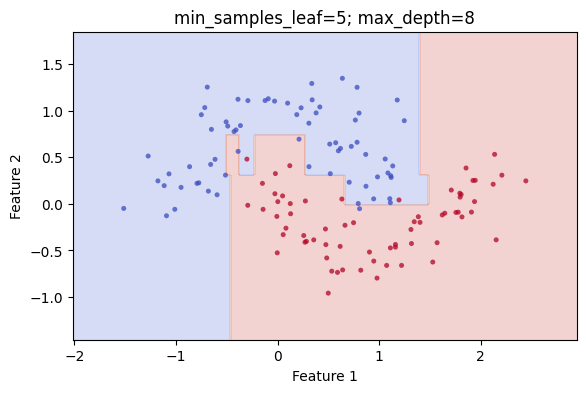

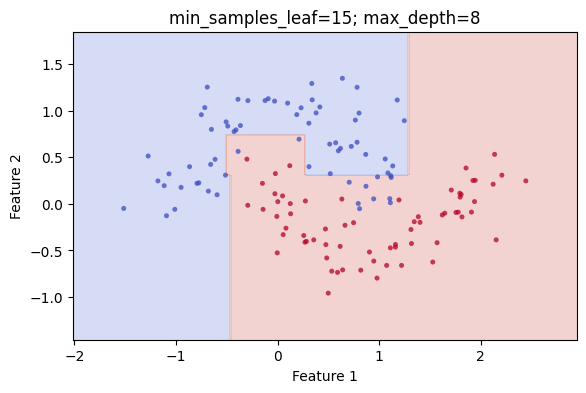

,min_samples_leaf,train_accuracy,test_accuracy,nodes,leaves
0,1,0.994,0.956,49,25
1,5,0.971,0.963,37,19
2,15,0.927,0.911,25,13


In [12]:
# CHALLENGE 2 — STUDENT MODIFICATION
# TODO: change [1] to [1, 5, 15]
leaf_values = [1, 5, 15]
results=[]
for leaf in leaf_values:
    m=classification_model(X_train, y_train, depth=8, leaf=leaf)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'min_samples_leaf':leaf, **r})
    fig, ax=plt.subplots(figsize=(6.5,4))
    draw_boundary(m, X_test, y_test, f'min_samples_leaf={leaf}; max_depth=8', ax)
    plt.show()
display(pd.DataFrame(results).round(3))

### Challenge 3 — Dataset Variability (Diagrams 1, 3, and 6)
**Required modification:** Change `modified_noise = 0.22` to **`0.38`**. Compare with Diagram 1 and the original baseline results. Recreate the dataset **and retrain**; old models must not be applied to a newly generated dataset when making this comparison. Report test accuracy and show the updated scatter plot and boundary.

**Interpretation (3–5 sentences):** How does overlap affect the tree's decisions and errors? Is the observed performance difference supported by test results?

```markdown
### 🔍 SCREENSHOT HIGHLIGHT — CHALLENGE 3
* **Default Value:** `modified_noise = 0.22`
* **Modified Value:** `modified_noise = 0.38`
* **Focus:** Examine the increased class overlap and its direct impact on overall test accuracy and the confusion matrix.
```

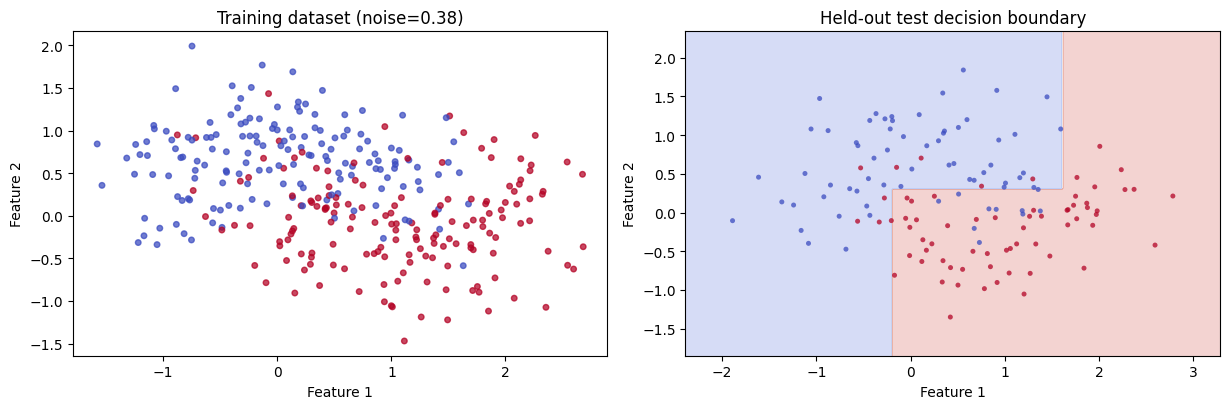

Baseline noise: 0.22 | modified noise: 0.38
New-data scores: {'train_accuracy': 0.8698412698412699, 'test_accuracy': 0.8666666666666667, 'nodes': 13, 'leaves': np.int64(7)}


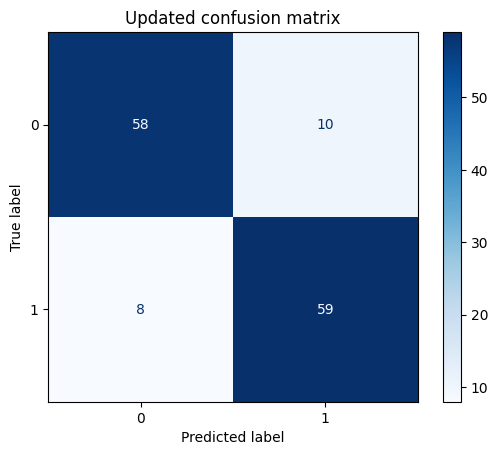

In [11]:
# CHALLENGE 3 — STUDENT MODIFICATION
# TODO: change modified_noise from 0.22 to 0.38
modified_noise = 0.38
Xa, Xb, ya, yb = classification_data(noise=modified_noise)
changed=classification_model(Xa, ya, depth=BASELINE_DEPTH)
fig, axes=plt.subplots(1,2,figsize=(12.4,4.2))
axes[0].scatter(Xa[:,0], Xa[:,1], c=ya, cmap='coolwarm', s=16, alpha=.73)
axes[0].set(title=f'Training dataset (noise={modified_noise})', xlabel='Feature 1', ylabel='Feature 2')
draw_boundary(changed, Xb, yb, 'Held-out test decision boundary', axes[1])
plt.tight_layout(); plt.show()
print('Baseline noise:', BASELINE_NOISE, '| modified noise:', modified_noise)
print('New-data scores:', classification_scores(changed, Xa, Xb, ya, yb))
ConfusionMatrixDisplay.from_predictions(yb, changed.predict(Xb), cmap='Blues', values_format='d')
plt.title('Updated confusion matrix'); plt.show()

### Challenge 4 — Confusion Matrix Analysis (Diagram 6)
**Required modification:** Replace `matrix_depths = [3]` with **`[2, 8]`**. Train and evaluate each model on the **same original split**. Identify the number of true positives, true negatives, false positives, and false negatives for class 1; also compare precision, recall, and test accuracy.

**Interpretation (3–5 sentences):** Which error types changed? Which depth would you select based on held-out performance, and why?

```markdown
### 🔍  HIGHLIGHT — CHALLENGE 4
* **Default Value:** `matrix_depths = [3]`
* **Modified Value:** `matrix_depths = [2, 8]`
* **Focus:** Compare detailed metrics (True Positives, False Positives, Precision, Recall) between shallow and deep trees.
```

Depth 2: TN=58, FP=10, FN=3, TP=64; test accuracy=0.904
              precision    recall  f1-score   support

           0       0.95      0.85      0.90        68
           1       0.86      0.96      0.91        67

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



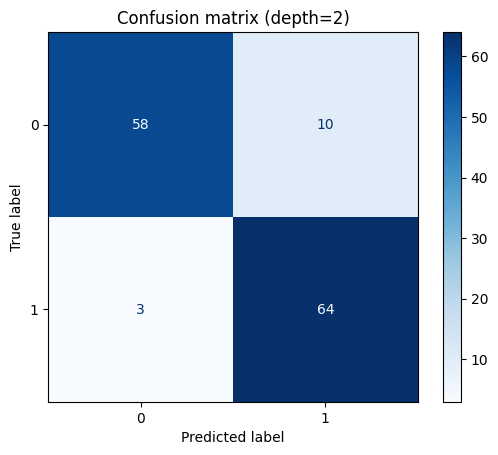

Depth 8: TN=65, FP=3, FN=3, TP=64; test accuracy=0.956
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        68
           1       0.96      0.96      0.96        67

    accuracy                           0.96       135
   macro avg       0.96      0.96      0.96       135
weighted avg       0.96      0.96      0.96       135



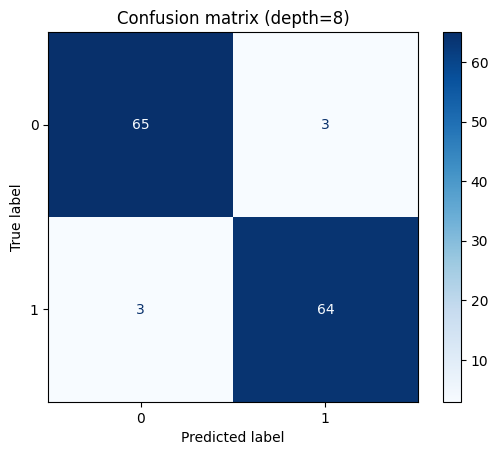

In [10]:
# CHALLENGE 4 — STUDENT MODIFICATION
# TODO: change [3] to [2, 8]
matrix_depths = [2, 8]
for d in matrix_depths:
    m=classification_model(X_train, y_train, depth=d)
    p=m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0,1]).ravel()
    print(f'Depth {d}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; test accuracy={accuracy_score(y_test,p):.3f}')
    print(classification_report(y_test,p,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,p,labels=[0,1],cmap='Blues',values_format='d')
    plt.title(f'Confusion matrix (depth={d})'); plt.show()

### Challenge 5 — Decision Tree Regression (Diagram 9)
**Required modification:** Replace `regression_depths = [4]` with **`[2, 4, 10]`**. Compare the three prediction curves, number of leaves, training RMSE, and held-out test RMSE.

**Interpretation (3–5 sentences):** Which curve is most complex? Does the lowest training error achieve the lowest test error? Explain the stepwise behavior.

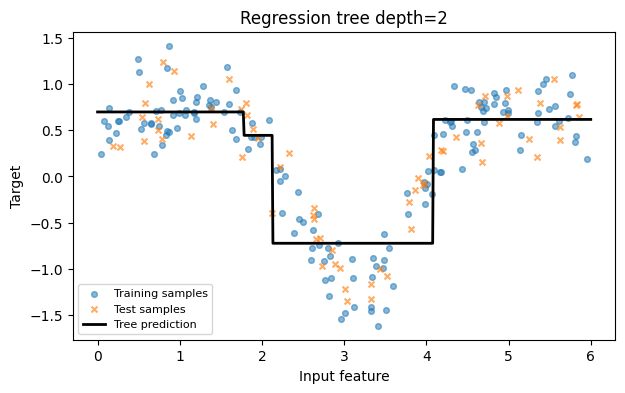

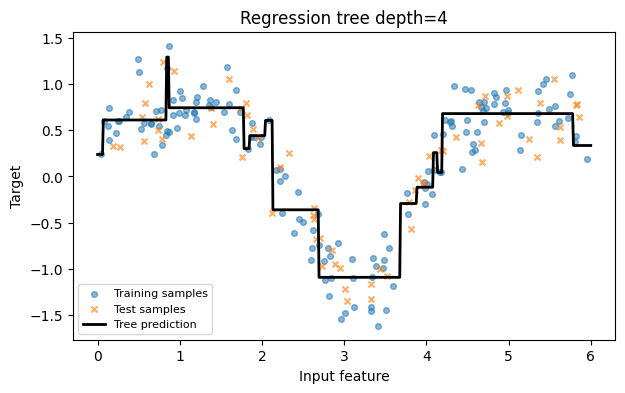

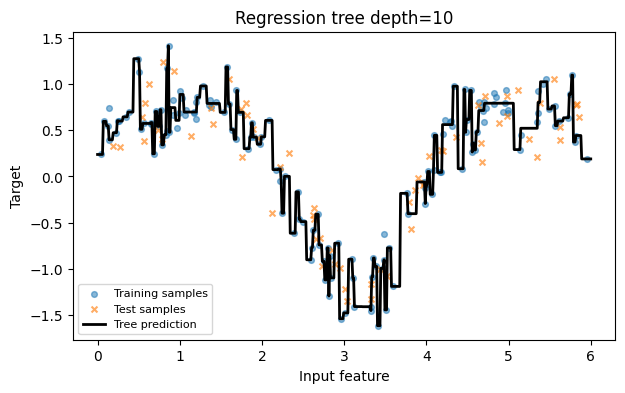

,depth,leaves,train_rmse,test_rmse
0,2,4,0.339,0.380
1,4,15,0.221,0.280
2,10,123,0.036,0.296


In [13]:
# CHALLENGE 5 — STUDENT MODIFICATION
# TODO: change [4] to [2, 4, 10]
regression_depths = [2, 4, 10]
results=[]
for d in regression_depths:
    m=regression_model(Xr_train, yr_train, depth=d)
    results.append({'depth': d, 'leaves': m.get_n_leaves(),
                    'train_rmse': regression_rmse(m, Xr_train, yr_train),
                    'test_rmse': regression_rmse(m, Xr_test, yr_test)})
    fig, ax=plt.subplots(figsize=(7,4))
    draw_regression_curve(m, Xr_train, yr_train, Xr_test, yr_test, f'Regression tree depth={d}', ax)
    plt.show()
display(pd.DataFrame(results).round(3))

## IV. Submission Checklist
- **Executed, modified notebook** containing comparisons and a 3–5 sentence Markdown interpretation after *each* challenge.
- **PDF activity report** with screenshots of baseline versus modified outputs and relevant test metrics for each challenge.
- **Overall reflection:** one paragraph of **5–7 sentences** addressing Decision Tree classification vs regression, the impact of depth and leaf size, overfitting/generalization, and your strongest evidence-based observation.

**Filenames:** `Lastname_Firstname_DecisionTree_Activity.ipynb` and `Lastname_Firstname_DecisionTree_Report.pdf`.

**Assessment (100 points):** Execution/modifications **25**; five challenges **25**; evidence-based interpretations **30**; reflection **10**; organization and completeness **10**.

**Important:** A depth-8 tree may appear truncated in a visualization even though the fitted model uses all allowed levels. Use the printed node/leaf counts and held-out metrics to support your conclusions. Never select a model solely from its training score.